# CNN Model

In [1]:
import sys
from mly.datatools import *
from mly.tools import toCategorical
import time, os
import numpy as np
import pickle
import keras
from scipy.signal import stft
from math import ceil
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential, load_model, Model
from tensorflow.keras.layers import Dense,Conv1D, MaxPool1D, Flatten, Input ,Activation, SpatialDropout2D
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization, GlobalAveragePooling2D, AveragePooling2D
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint ,ReduceLROnPlateau
from tensorflow.keras import optimizers, initializers
from tensorflow.config import threading
from mly.plugins import *
from sklearn.metrics import confusion_matrix, classification_report

threading.set_inter_op_parallelism_threads(1)
threading.set_intra_op_parallelism_threads(1)

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

%matplotlib inline

/home/jakub.rutkowski/.conda/envs/mly-base/lib/python3.10/site-packages/gwpy/time/__init__.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  from lal import LIGOTimeGPS
2026-08-25 05:51:02.642773: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA
To enable them

In [2]:
def stftGenFunction(strain, fs):
    stft_list = []
    for st in strain:
        f, t, Zxx = stft(st, fs=fs, nperseg=64, noverlap=32)
        Zxx_norm = np.abs(Zxx)
        stft_list.append(Zxx_norm)
    return np.array(stft_list), f, t

def stftPlotFunction(strain, fs, detectors, data=None):
    colors = {'H': 'Reds_r', 'L': 'Blues_r', 'V': 'Greens_r', 'K': 'Oranges_r', 'I': 'Purples_r'}
    Zxx_array, f, t = data
    for i, det in enumerate(detectors):
        plt.figure(figsize=(10, 6))
        plt.pcolormesh(t, f, Zxx_array[i], cmap=colors[det], shading='auto')
        plt.xlabel('Time (s)')
        plt.ylabel('Frequency (Hz)')
        plt.title(f'Detector {det}')
        plt.colorbar(label='Amplitude')
        plt.ylim(0, 512)
        plt.show()
        
stft_plugin = PlugIn(name='stft',
                     genFunction=stftGenFunction,
                     attributes=['strain', 'fs'],
                     plotFunction=stftPlotFunction,
                     plotAttributes=['strain', 'fs', 'detectors'])

# Importing wavefroms

In [3]:
Set = DataSet.fusion(['/home/jakub.rutkowski/project/waveform-generation/waveform-sets/wnb_signal_set_10000.pkl',
                    '/home/jakub.rutkowski/project/waveform-generation/waveform-sets/wnb_glitch_set_10000.pkl', 
                    '/home/jakub.rutkowski/project/waveform-generation/waveform-sets/gaussian_noise_set_10000.pkl'],
                     [5000, 10000, 10000]
                     )

# Building CNN

In [4]:
X = Set.exportData('strain',shape=(None,1024,3))

C = Set.exportData('correlation',shape=(None,60,3))

Y0 = Set.exportLabels('type')

F = np.array([pod.stft[0] for pod in Set])
F = F.transpose(0, 2, 3, 1)  
F.shape

DataSet with shape (25000, 1024, 3) is exported
DataSet with shape (25000, 60, 3) is exported
Labels ['type'] with shape (25000,) are exported


(25000, 33, 33, 3)

In [5]:
Y,translation = toCategorical(Y0,from_mapping=['noise','signal'])

In [6]:
input_stft = Input(shape = (33, 33, 3), name = 'TF map' )
input_stft.shape

TensorShape([None, 33, 33, 3])

In [7]:
F_train, F_test, Y_train, Y_test = train_test_split(F, Y, test_size=0.2, random_state=0)

In [8]:
LR=0.00075

opt=optimizers.Nadam(learning_rate= LR
                     , beta_1=0.9
                     , beta_2=0.999
                     , epsilon=1e-8
                     , schedule_decay=0.000002)

es = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=5, restore_best_weights=True)

rp = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1, mode='min', min_delta=0.00001, cooldown=0, min_lr=0.00001)

checkpoint_cb = keras.callbacks.ModelCheckpoint(
    '/home/jakub.rutkowski/project/waveform-generation/model/best_CNN_model.keras',
    save_best_only=True,
    monitor='val_loss',
    mode='min'
)

In [9]:
#x = Conv2D(filters=16, kernel_size=(2,2), padding='same')(input_stft)
#x = Activation('relu')(x)
#x = MaxPooling2D((2,2), padding='same')(x)
#x = SpatialDropout2D(0.15)(x) 

x = Conv2D(filters=32, kernel_size=(2,2), padding='same')(input_stft)
x = Activation('relu')(x)
x = MaxPooling2D((2,2), padding='same')(x)
x = SpatialDropout2D(0.15)(x) 

x = Conv2D(filters=64, kernel_size=(2,2), padding='same')(x)
x = Activation('relu')(x)
x = MaxPooling2D((2,2), padding='same')(x)
x = SpatialDropout2D(0.15)(x) 

x = Conv2D(filters=128, kernel_size=(2,2), padding='same')(x)
x = Activation('relu')(x)
x = MaxPooling2D((2,2), padding='same')(x)
x = SpatialDropout2D(0.15)(x) 

#x = Flatten(name='final_stft')(x)
x = GlobalAveragePooling2D(name='final_stft')(x)

x = Dense(512)(x)
x = BatchNormalization()(x)
x = Activation('relu')(x)
x = Dropout(0.5)(x)

x = Dense(256)(x)
x = BatchNormalization()(x)
x = Activation('relu')(x)
x = Dropout(0.5)(x)

output = Dense(2, activation='softmax')(x)

model = Model(inputs=input_stft, outputs=output)

model.compile(optimizer=opt,
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 TF map (InputLayer)         [(None, 33, 33, 3)]       0         
                                                                 
 conv2d (Conv2D)             (None, 33, 33, 32)        416       
                                                                 
 activation (Activation)     (None, 33, 33, 32)        0         
                                                                 
 max_pooling2d (MaxPooling2D  (None, 17, 17, 32)       0         
 )                                                               
                                                                 
 spatial_dropout2d (SpatialD  (None, 17, 17, 32)       0         
 ropout2D)                                                       
                                                                 
 conv2d_1 (Conv2D)           (None, 17, 17, 64)        8256  

2026-08-25 05:51:10.246843: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcuda.so.1'; dlerror: libcuda.so.1: cannot open shared object file: No such file or directory
2026-08-25 05:51:10.246879: W tensorflow/stream_executor/cuda/cuda_driver.cc:263] failed call to cuInit: UNKNOWN ERROR (303)
2026-08-25 05:51:10.246900: I tensorflow/stream_executor/cuda/cuda_diagnostics.cc:156] kernel driver does not appear to be running on this host (citlogin6): /proc/driver/nvidia/version does not exist
2026-08-25 05:51:10.247098: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [10]:
history = model.fit(F_train, Y_train
                    , epochs=150
                    , batch_size=300
                    , validation_data=(F_test, Y_test)
                    , callbacks=[es, 
                                 rp,
                                 checkpoint_cb
                                 ])

Epoch 1/150


67/67 [==============================] - 13s 177ms/step - loss: 0.6766 - accuracy: 0.7155 - val_loss: 0.5807 - val_accuracy: 0.8004 - lr: 7.5000e-04
Epoch 2/150
67/67 [==============================] - 11s 159ms/step - loss: 0.5227 - accuracy: 0.7893 - val_loss: 0.4959 - val_accuracy: 0.8004 - lr: 7.5000e-04
Epoch 3/150
67/67 [==============================] - 11s 169ms/step - loss: 0.2821 - accuracy: 0.8953 - val_loss: 0.4833 - val_accuracy: 0.8004 - lr: 7.5000e-04
Epoch 4/150
67/67 [==============================] - 13s 195ms/step - loss: 0.1787 - accuracy: 0.9406 - val_loss: 0.4533 - val_accuracy: 0.8004 - lr: 7.5000e-04
Epoch 5/150
67/67 [==============================] - 11s 168ms/step - loss: 0.1520 - accuracy: 0.9505 - val_loss: 0.4534 - val_accuracy: 0.8372 - lr: 7.5000e-04
Epoch 6/150
67/67 [==============================] - 13s 201ms/step - loss: 0.1380 - accuracy: 0.9564 - val_loss: 0.4929 - val_accuracy: 0.9234 - lr: 7.5000e-04
Epoch 7/150
67/67 [===========================

# CNN test results

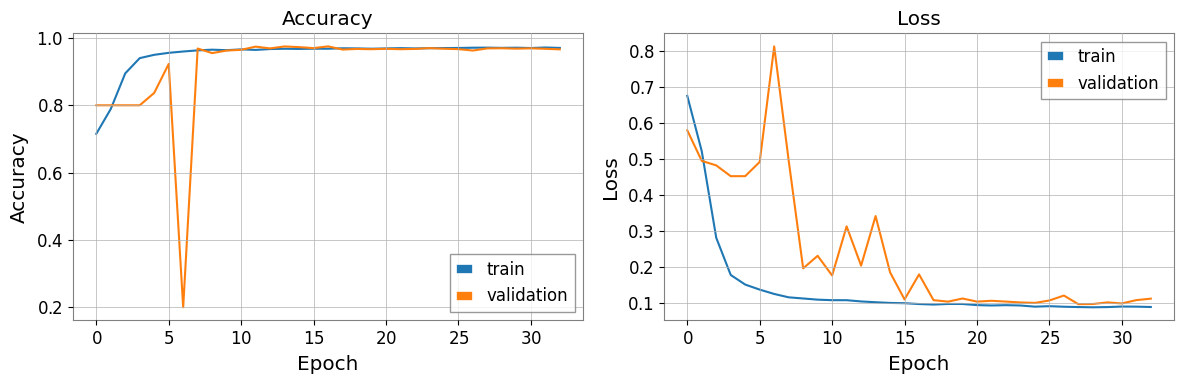

In [11]:
# Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(history.history['accuracy'], label='train')
ax1.plot(history.history['val_accuracy'], label='validation')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.set_title('Accuracy')
#ax1.set_ylim(0, max(history.history['val_accuracy']) * 1.1)

ax2.plot(history.history['loss'], label='train')
ax2.plot(history.history['val_loss'], label='validation')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.set_title('Loss')
#ax2.set_ylim(0, max(history.history['val_loss']) * 1.1)

plt.tight_layout()
plt.show()

In [12]:
y_pred = model.predict(F_test).argmax(axis=1)
y_true = Y_test.argmax(axis=1)

print(confusion_matrix(y_true, y_pred))
print(classification_report(y_true, y_pred, target_names=['noise', 'signal']))

157/157 [==============================] - 1s 5ms/step
[[3996    6]
 [ 146  852]]
              precision    recall  f1-score   support

       noise       0.96      1.00      0.98      4002
      signal       0.99      0.85      0.92       998

    accuracy                           0.97      5000
   macro avg       0.98      0.93      0.95      5000
weighted avg       0.97      0.97      0.97      5000



# Testing results using CSG waveforms

# Low Frequency

In [13]:
TestSetLowF = DataSet.fusion(['/home/jakub.rutkowski/project/waveform-generation/waveform-sets/csg_lowfreq_signal_set.pkl',  
                    '/home/jakub.rutkowski/project/waveform-generation/waveform-sets/csg_lowfreq_glitch_set.pkl'],
                     [200,200])

In [14]:
F_test = np.array([pod.stft[0] for pod in TestSetLowF])
F_test = F_test.transpose(0, 2, 3, 1)  

Y0 = TestSetLowF.exportLabels('type')

Labels ['type'] with shape (400,) are exported


In [15]:
Y_test,translation = toCategorical(Y0,from_mapping=['noise','signal'])

In [16]:
test_loss, test_accuracy = model.evaluate(F_test, Y_test, verbose=1)

13/13 [==============================] - 0s 4ms/step - loss: 0.2114 - accuracy: 0.9250


In [17]:
print(confusion_matrix(Y_test.argmax(axis=1), model.predict(F_test).argmax(axis=1)))
print(classification_report(Y_test.argmax(axis=1), model.predict(F_test).argmax(axis=1), target_names=['noise', 'signal']))

13/13 [==============================] - 0s 4ms/step
[[200   0]
 [ 30 170]]
13/13 [==============================] - 0s 5ms/step
              precision    recall  f1-score   support

       noise       0.87      1.00      0.93       200
      signal       1.00      0.85      0.92       200

    accuracy                           0.93       400
   macro avg       0.93      0.93      0.92       400
weighted avg       0.93      0.93      0.92       400



# High Frequency

In [18]:
TestSetHighF = DataSet.fusion(['/home/jakub.rutkowski/project/waveform-generation/waveform-sets/csg_highfreq_signal_set.pkl',  
                    '/home/jakub.rutkowski/project/waveform-generation/waveform-sets/csg_highfreq_glitch_set.pkl'],
                     [200,200]        )

In [19]:
F_test = np.array([pod.stft[0] for pod in TestSetHighF])
F_test = F_test.transpose(0, 2, 3, 1)  

Y0 = TestSetHighF.exportLabels('type')

Labels ['type'] with shape (400,) are exported


In [20]:
Y_test,translation = toCategorical(Y0,from_mapping=['noise','signal'])

In [21]:
test_loss, test_accuracy = model.evaluate(F_test, Y_test, verbose=1)

13/13 [==============================] - 0s 5ms/step - loss: 0.1534 - accuracy: 0.9425


In [22]:
print(confusion_matrix(Y_test.argmax(axis=1), model.predict(F_test).argmax(axis=1)))
print(classification_report(Y_test.argmax(axis=1), model.predict(F_test).argmax(axis=1), target_names=['noise', 'signal']))

13/13 [==============================] - 0s 3ms/step
[[200   0]
 [ 23 177]]
13/13 [==============================] - 0s 5ms/step
              precision    recall  f1-score   support

       noise       0.90      1.00      0.95       200
      signal       1.00      0.89      0.94       200

    accuracy                           0.94       400
   macro avg       0.95      0.94      0.94       400
weighted avg       0.95      0.94      0.94       400



# SNR efficiency

In [23]:
base_path = '/home/jakub.rutkowski/project/waveform-generation/waveform-sets/'

lowfreq_snrs = [0, 2, 5, 8, 10, 12, 15, 20, 25, 30, 35, 40, 45, 50]
highfreq_snrs = [0, 2, 5, 8, 10, 12, 15, 20, 25, 30, 35, 40, 45, 50]
cbc_snrs = [0, 2, 5, 8, 10, 12, 15, 20, 25, 30, 35, 40, 45, 50]
wnb_test_snrs = [0, 2, 5, 8, 10, 12, 15, 20, 25, 30, 35, 40, 45, 50]

datasets = {
    'lowfreq': {snr: DataSet.load(f'{base_path}lowfreq_test_set_noise_snr{snr}.pkl') for snr in lowfreq_snrs},
    'highfreq': {snr: DataSet.load(f'{base_path}highfreq_test_set_noise_snr{snr}.pkl') for snr in highfreq_snrs},
    'cbc': {snr: DataSet.load(f'{base_path}cbc_test_set_noise_snr{snr}.pkl') for snr in cbc_snrs},
    'wnb_test': {snr: DataSet.load(f'{base_path}wnb_test_test_set_noise_snr{snr}.pkl') for snr in wnb_test_snrs},
}

In [24]:
results = {}

for freq_band, snr_dict in datasets.items():
    for snr, dataset in snr_dict.items():

        X_test = np.array([pod.stft[0] for pod in dataset])
        X_test = X_test.transpose(0, 2, 3, 1)

        Y0 = dataset.exportLabels('type')
        Y_test, translation = toCategorical(Y0, from_mapping=['noise', 'signal'])

        preds = model.predict(X_test)
        pred_labels = np.argmax(preds, axis=1)
        true_labels = np.argmax(Y_test, axis=1)

        detection_rate = (pred_labels == true_labels).mean() * 100

        results[(freq_band, snr)] = detection_rate
        #print(f"{freq_band} SNR={snr}: {detection_rate:.2f}% correctly detected")

Labels ['type'] with shape (150,) are exported
5/5 [==============================] - 0s 5ms/step
Labels ['type'] with shape (150,) are exported
5/5 [==============================] - 0s 4ms/step
Labels ['type'] with shape (150,) are exported
5/5 [==============================] - 0s 5ms/step
Labels ['type'] with shape (150,) are exported
5/5 [==============================] - 0s 7ms/step
Labels ['type'] with shape (150,) are exported
5/5 [==============================] - 0s 5ms/step
Labels ['type'] with shape (150,) are exported
5/5 [==============================] - 0s 5ms/step
Labels ['type'] with shape (150,) are exported
5/5 [==============================] - 0s 4ms/step
Labels ['type'] with shape (150,) are exported
5/5 [==============================] - 0s 4ms/step
Labels ['type'] with shape (150,) are exported
5/5 [==============================] - 0s 4ms/step
Labels ['type'] with shape (150,) are exported
5/5 [==============================] - 0s 4ms/step
Labels ['type'] with

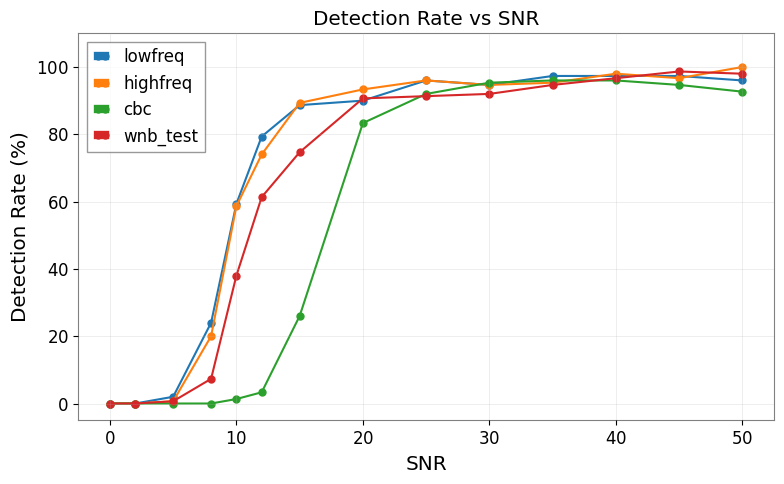

In [25]:
fig, ax = plt.subplots(figsize=(8, 5))

for freq_band in datasets.keys():
    snrs = sorted(datasets[freq_band].keys())
    rates = [results[(freq_band, snr)] for snr in snrs]
    ax.plot(snrs, rates, marker='o',  markersize=5, label=freq_band)

ax.set_xlabel('SNR')
ax.set_ylabel('Detection Rate (%)')
ax.set_title('Detection Rate vs SNR')
ax.set_ylim(-5, 110)
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
#plt.savefig('detection_rate_vs_snr.png', dpi=150)
plt.show()

# Real Noise

313/313 [==============================] - 2s 6ms/step


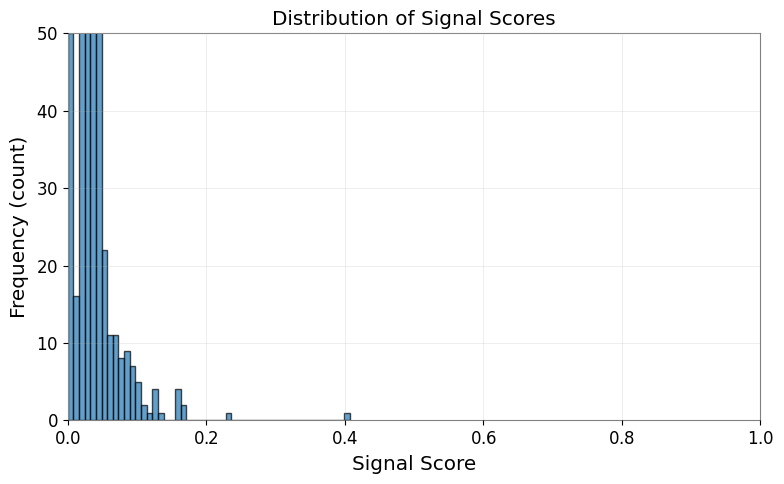

9928
0.40744728


In [26]:
realnoise = DataSet.fusion(['/home/jakub.rutkowski/project/waveform-generation/waveform-sets/real_noise_set.pkl',
                            ])

X_test = np.array([pod.stft[0] for pod in realnoise])
X_test = X_test.transpose(0, 2, 3, 1)

preds = model.predict(X_test)

signal_class_index = np.argmax(translation['signal']) 
signal_scores = preds[:, signal_class_index]

sorted_scores = np.sort(signal_scores)[::-1]

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(signal_scores, bins=50, edgecolor='black', alpha=0.7)

ax.set_xlabel('Signal Score')
ax.set_ylabel('Frequency (count)')
ax.set_title('Distribution of Signal Scores')
ax.set_xlim(0, 1)
#ax.legend()
ax.grid(True, alpha=0.3)
ax.set_ylim(0, 50)

plt.tight_layout()
#plt.savefig('signal_score_histogram.png', dpi=150)
plt.show()

unique_values = np.unique(sorted_scores)
print(len(unique_values))
print(max(signal_scores))

# SNR detection % with adjusted threshold

In [27]:
datasets = {
    'lowfreq': {snr: DataSet.load(f'{base_path}lowfreq_test_set_noise_snr{snr}.pkl') for snr in lowfreq_snrs},
    'highfreq': {snr: DataSet.load(f'{base_path}highfreq_test_set_noise_snr{snr}.pkl') for snr in highfreq_snrs},
    'cbc': {snr: DataSet.load(f'{base_path}cbc_test_set_noise_snr{snr}.pkl') for snr in cbc_snrs},
    'wnb_test': {snr: DataSet.load(f'{base_path}wnb_test_test_set_noise_snr{snr}.pkl') for snr in wnb_test_snrs},
}

results = {}

for freq_band, snr_dict in datasets.items():
    for snr, dataset in snr_dict.items():

        X_test = np.array([pod.stft[0] for pod in dataset])
        X_test = X_test.transpose(0, 2, 3, 1)

        Y0 = dataset.exportLabels('type')
        Y_test, translation = toCategorical(Y0, from_mapping=['noise', 'signal'])

        preds = model.predict(X_test)
        threshold = max(signal_scores)
        pred_labels = (preds[:, 1] >= threshold).astype(int)
        true_labels = np.argmax(Y_test, axis=1)

        detection_rate = (pred_labels == true_labels).mean() * 100

        results[(freq_band, snr)] = detection_rate

Labels ['type'] with shape (150,) are exported
5/5 [==============================] - 0s 6ms/step
Labels ['type'] with shape (150,) are exported
5/5 [==============================] - 0s 5ms/step
Labels ['type'] with shape (150,) are exported
5/5 [==============================] - 0s 6ms/step
Labels ['type'] with shape (150,) are exported
5/5 [==============================] - 0s 5ms/step
Labels ['type'] with shape (150,) are exported
5/5 [==============================] - 0s 5ms/step
Labels ['type'] with shape (150,) are exported
5/5 [==============================] - 0s 4ms/step
Labels ['type'] with shape (150,) are exported


5/5 [==============================] - 0s 5ms/step
Labels ['type'] with shape (150,) are exported
5/5 [==============================] - 0s 4ms/step
Labels ['type'] with shape (150,) are exported
5/5 [==============================] - 0s 4ms/step
Labels ['type'] with shape (150,) are exported
5/5 [==============================] - 0s 3ms/step
Labels ['type'] with shape (150,) are exported
5/5 [==============================] - 0s 4ms/step
Labels ['type'] with shape (150,) are exported
5/5 [==============================] - 0s 3ms/step
Labels ['type'] with shape (150,) are exported
5/5 [==============================] - 0s 4ms/step
Labels ['type'] with shape (150,) are exported
5/5 [==============================] - 0s 3ms/step
Labels ['type'] with shape (150,) are exported
5/5 [==============================] - 0s 5ms/step
Labels ['type'] with shape (150,) are exported
5/5 [==============================] - 0s 4ms/step
Labels ['type'] with shape (150,) are exported
5/5 [===============

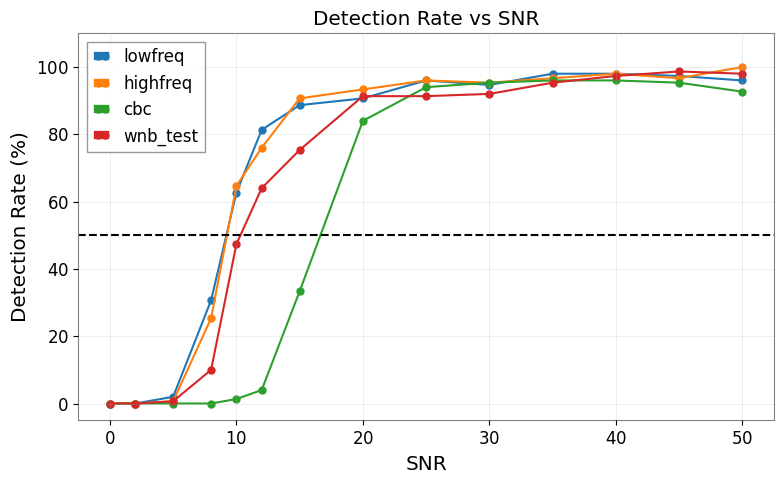

In [28]:
fig, ax = plt.subplots(figsize=(8, 5))

for freq_band in datasets.keys():
    snrs = sorted(datasets[freq_band].keys())
    rates = [results[(freq_band, snr)] for snr in snrs]
    ax.plot(snrs, rates, marker='o',  markersize=5, label=freq_band)

ax.set_xlabel('SNR')
ax.set_ylabel('Detection Rate (%)')
ax.set_title('Detection Rate vs SNR')
ax.set_ylim(-5, 110)
ax.axhline(50, color = 'k', linestyle = '--')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
#plt.savefig('detection_rate_vs_snr.png', dpi=150)
plt.show()